# Find SWOT passes in a time interval and region

This example predicts when nominal SWOT ground tracks cross a geographic bounding box. Times are UTC and the region is `[longitude_min, longitude_max, latitude_min, latitude_max]`.

In [1]:
import sys
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import satpass

print(f"SatPass version: {satpass.__version__}")

import pandas as pd

SatPass version: 0.1.0


## Set the time interval and region

In [2]:
start_time = pd.Timestamp("2027-04-01 00:00:00")
end_time = pd.Timestamp("2027-04-30 23:59:59")
region = [150.0, 160.0, -55.0, -50.0]

## Calculate predicted passes

In [3]:
nominal = satpass.NominalTrack('sw')
tracks = nominal.select_in_area(region)

In [5]:
passes = satpass.sat_pass(
    mission="sw",
    date=[start_time, end_time],
    area=region,
)

passes

,track,direction,cycle,lon0_360,time,subcycle_rank,subcycle,subcycle_global
2027-04-01 23:39:00,433,asc,65.0,155.047606,2027-04-01 23:39:00,2,1.0,1.0
2027-04-02 22:22:00,461,asc,65.0,152.693440,2027-04-02 22:22:00,3,1.0,1.0
2027-04-03 22:16:00,489,asc,65.0,150.350341,2027-04-03 22:16:00,4,1.0,1.0
2027-04-05 11:29:00,532,des,65.0,158.991210,2027-04-05 11:29:00,0,3.0,3.0
2027-04-06 11:23:00,560,des,65.0,156.493616,2027-04-06 11:23:00,1,3.0,3.0
2027-04-07 13:31:00,4,des,66.0,153.994863,2027-04-07 13:31:00,2,3.0,3.0
2027-04-08 13:25:00,32,des,66.0,151.496169,2027-04-08 13:25:00,3,3.0,3.0
2027-04-09 13:19:00,60,des,66.0,148.997764,2027-04-09 13:19:00,4,3.0,3.0
2027-04-09 22:23:00,71,asc,66.0,161.216992,2027-04-09 22:23:00,0,0.0,0.0
2027-04-10 22:06:00,99,asc,66.0,158.861344,2027-04-10 22:06:00,1,0.0,0.0


## Plot the tracks crossing the region in the given time interval

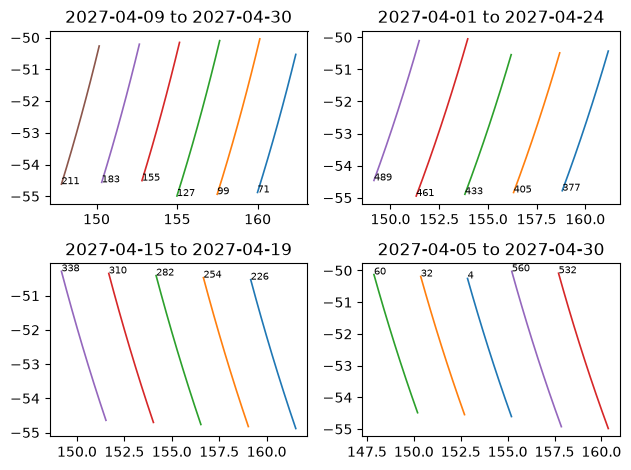

In [26]:
swot = satpass.NominalTrack("sw")



subcycle = 1

for i, subcycle in enumerate(range(4)):

    tracks = swot.select_in_area(region, extend_to_latitude_bounds=True)

    selected_track_numbers = set(passes.where(passes.subcycle == subcycle)["track"]) if not passes.empty else set()
    tracks = tracks[tracks["track"].isin(selected_track_numbers)]
    
    ax = plt.subplot(2, 2, i+1)
    
    for track_number, track in tracks.groupby("track"):
        ax.plot(
            track["lon"],
            track["lat"],
            linewidth=1.2,
        )
        ax.text(track["lon"].iloc[0], track["lat"].iloc[0], str(track_number), fontsize=7)
        times = pd.DatetimeIndex(passes.where(passes.subcycle == subcycle).dropna().time.values)
        ax.set_title(f'{times[0].date()} to {times[-1].date()}')

plt.tight_layout()

In [21]:
times

2027-04-05 11:29:00   2027-04-05 11:29:00
2027-04-06 11:23:00   2027-04-06 11:23:00
2027-04-07 13:31:00   2027-04-07 13:31:00
2027-04-08 13:25:00   2027-04-08 13:25:00
2027-04-09 13:19:00   2027-04-09 13:19:00
2027-04-26 08:14:00   2027-04-26 08:14:00
2027-04-27 08:08:00   2027-04-27 08:08:00
2027-04-28 10:16:00   2027-04-28 10:16:00
2027-04-29 10:10:00   2027-04-29 10:10:00
2027-04-30 10:04:00   2027-04-30 10:04:00
Name: time, dtype: datetime64[ns]